<a href="https://colab.research.google.com/github/Violetaaa/tfg-learning/blob/main/04_gis_with_python/09_clasificacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6.9 Clasificación de datos (resumen)

Resumen del capítulo *Data classification* de *Python for Geographic Data Analysis* (Tenkanen et al., pythongis.org), reducido a lo que se usa en el TFG. El libro usa datos de Helsinki; aquí se usan tus datos de Asturias.

**Idea clave:** agrupar valores numéricos en clases (por ejemplo, tiempo al hospital de 0–15, 15–30… minutos), sobre todo para **mapas temáticos** (coropletas). La librería es `mapclassify`, y GeoPandas la usa por dentro con `plot(scheme=...)`.

Te servirá para las figuras de la memoria. **El método de clasificación cambia el mensaje del mapa**, así que hay que elegirlo y justificarlo.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

# Folder that contains raw/ and asturias_miteco.gpkg. In Colab, e.g. Path("/content/drive/MyDrive/tfg/datos").
DATA_DIR = Path("/content/drive/MyDrive/tfg/")
CRS_METRES = "EPSG:25830"


def load_layer(pattern):
    """Read the latest raw download matching a pattern and reproject it to metres."""
    path = sorted(DATA_DIR.glob(f"sitpa_raw_data/{pattern}"))[-1]
    return gpd.read_file(path).to_crs(CRS_METRES)


municipalities = gpd.read_file(DATA_DIR / "miteco_data/out/asturias_miteco.gpkg").to_crs(CRS_METRES)
pharmacies = load_layer("farmacias_botiquines__farmacias_*.geojson")

import mapclassify  # pip install mapclassify (needed for plot(scheme=...))

# tipo_hosp: MITECO time to the reference hospital. Unit not documented (probably minutes, see hallazgos_miteco.md)
times = municipalities["tipo_hosp"]
times.describe().round(1)

,tipo_hosp
count,78.0
mean,19.7
std,13.4
min,0.9
25%,10.1
50%,17.3
75%,29.0
max,54.2


## Paso 1: mirar la distribución
Antes de elegir las clases, haz un histograma: con una distribución asimétrica (pocos concejos muy lejos), unas clases iguales dejan casi todo en una sola clase.

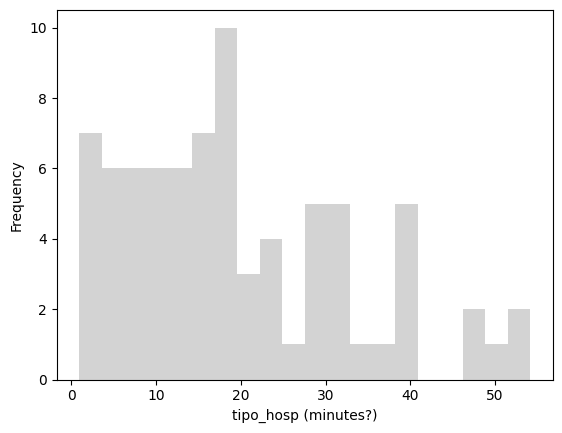

In [4]:
times.plot.hist(bins=20, color="lightgray")
plt.xlabel("tipo_hosp (minutes?)");

## Paso 2: elegir un esquema

| Esquema | Cómo corta | Cuándo |
|---|---|---|
| `Quantiles` | mismo **número de concejos** por clase | comparar posiciones relativas (el 20 % peor) |
| `NaturalBreaks` | busca cortes naturales en los datos | ver grupos reales; los cortes cambian si cambian los datos |
| `UserDefined` | cortes que eliges tú | **umbrales con significado** (15/30/45 min): comparables entre mapas y fáciles de explicar |

`EqualInterval` y `PrettyBreaks` (intervalos iguales o redondeados) existen, pero con datos asimétricos funcionan mal.

In [5]:
schemes = {
    "Quantiles": mapclassify.Quantiles(times, k=5),
    "NaturalBreaks": mapclassify.NaturalBreaks(times, k=5),
    "UserDefined": mapclassify.UserDefined(times, bins=[15, 30, 45]),
}
for name, classifier in schemes.items():
    print(f"{name:14} upper bounds: {classifier.bins.round(1)}  counts: {classifier.counts}")

Quantiles      upper bounds: [ 7.2 15.  19.2 31.2 54.2]  counts: [16 15 16 15 16]
NaturalBreaks  upper bounds: [11.2 22.9 32.4 40.2 54.2]  counts: [25 28 13  7  5]
UserDefined    upper bounds: [15.  30.  45.  54.2]  counts: [31 29 13  5]


`bins` son los límites superiores de cada clase y `counts`, cuántos concejos caen en cada una. Para guardar la clase como columna: `municipalities["class"] = classifier.yb`.

## Paso 3: el mapa
`plot(column=..., scheme=..., k=...)` clasifica y dibuja en un solo paso. Para cortes propios se usa `classification_kwds`.

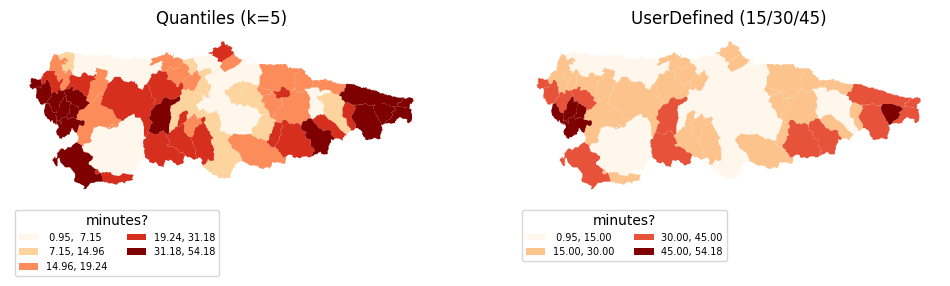

In [6]:
fig, axes = plt.subplots(ncols=2, figsize=(12, 4.5))
municipalities.plot(ax=axes[0], column="tipo_hosp", scheme="Quantiles", k=5, cmap="OrRd", legend=True,
                    legend_kwds={"title": "minutes?", "loc": "upper left", "bbox_to_anchor": (0, -0.05), "ncols": 2, "fontsize": 7})
municipalities.plot(ax=axes[1], column="tipo_hosp", scheme="UserDefined", classification_kwds={"bins": [15, 30, 45]},
                    cmap="OrRd", legend=True, legend_kwds={"title": "minutes?", "loc": "upper left", "bbox_to_anchor": (0, -0.05), "ncols": 2, "fontsize": 7})
for ax, title in zip(axes, ["Quantiles (k=5)", "UserDefined (15/30/45)"]):
    ax.set_title(title)
    ax.set_axis_off()

Mismos datos y dos impresiones distintas. Con cuantiles, 16 concejos (el 20 %) quedan en la clase más oscura, que empieza en 31. Con umbrales fijos, solo 5 superan los 45. **Inferencia:** para la memoria son más defendibles los umbrales fijos con significado. Si usas umbrales de referencia (por ejemplo, de una normativa o un informe), **necesitan fuente**.

## Clasificación por reglas
Combinar varios criterios con pandas. Ejemplo: concejos **sin farmacia y a más de 30 de un hospital**, el tipo de filtro que hará el agente en las preguntas de planificación. Recuerda poner paréntesis en cada condición.

In [7]:
rule = (municipalities["farmacias"] == 0) & (municipalities["tipo_hosp"] > 30)
municipalities.loc[rule, ["nombre", "farmacias", "tipo_hosp"]].sort_values("tipo_hosp", ascending=False)

,nombre,farmacias,tipo_hosp
45,Pesoz,0,54.177
69,Taramundi,0,39.302
28,Illano,0,38.780
60,San Tirso de Abres,0,37.143
49,Ponga,0,31.689


⚠️ `tipo_hosp` tiene los problemas anotados en `hallazgos_miteco.md`: la unidad no está documentada, se mide probablemente desde la capital del concejo y el «hospital» incluye centros privados. Úsalo para aprender y validar, pero no como dato final sin resolver eso.

## Lo que se ha omitido del capítulo
- `PrettyBreaks` y `EqualInterval` con sus figuras.
- Histogramas con las líneas de corte: se pueden hacer con `plt.axvline` sobre `classifier.bins`.
- Mapas interactivos con `.explore()`.

Documentación: https://pysal.org/mapclassify/